In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import json

EPILL = Path("../data/raw/epillid/ePillID_data")
MEDI_ROOT = Path("../data/raw/MEDISEG")
df = pd.read_csv(EPILL / "all_labels.csv")
cons = df[~df.is_ref]
per_type = cons.pilltype_id.value_counts()

print(df.shape, len(per_type))

OUT = Path("../data/processed")
OUT.mkdir(parents=True, exist_ok=True)

(13532, 9) 960


In [2]:
print((per_type >= 4).sum())
print((per_type == 5).sum())
folds_dir = EPILL / "folds"
for p in sorted(folds_dir.rglob("*.csv")):
    print(p.name)



f = pd.read_csv(next(folds_dir.rglob("*_all.csv")))

print(f.shape)
print(list(f.columns))
print(f.head())


648
425
pilltypeid_nih_sidelbls0.01_metric_5folds_0.csv
pilltypeid_nih_sidelbls0.01_metric_5folds_1.csv
pilltypeid_nih_sidelbls0.01_metric_5folds_2.csv
pilltypeid_nih_sidelbls0.01_metric_5folds_3.csv
pilltypeid_nih_sidelbls0.01_metric_5folds_4.csv
pilltypeid_nih_sidelbls0.01_metric_5folds_all.csv
(13532, 9)
['images', 'pilltype_id', 'label_code_id', 'prod_code_id', 'is_ref', 'is_front', 'is_new', 'image_path', 'label']
     images             pilltype_id  label_code_id  prod_code_id  is_ref  \
0     0.jpg  51285-0092-87_BE305F72          51285            92   False   
1    10.jpg  00093-0148-01_4629A34D             93           148   False   
2   100.jpg  00093-7248-06_7829BC3D             93          7248   False   
3  1003.jpg  00093-0928-06_6926B4E5             93           928   False   
4  1004.jpg  50111-0459-01_1C300E70          50111           459   False   

   is_front  is_new                      image_path                   label  
0     False   False     fcn_mix_weight/dc_

In [3]:
for p in sorted(folds_dir.glob("*.csv")):
    t = pd.read_csv(p)
    print(p.name, t.shape, "ref images:", t.is_ref.sum())
f = pd.read_csv(next(folds_dir.rglob("*_all.csv")))
print("same images as all_labels:", set(f.image_path) == set(df.image_path))
print("label == pilltype_id:", (f.label == f.pilltype_id).all())

same images as all_labels: True
label == pilltype_id: True


In [4]:
folds = {}
for i in range(5):
    folds[i] = pd.read_csv(next(folds_dir.rglob(f"*_{i}.csv")))

all_ids = pd.concat([folds[i].image_path for i in range(5)])
print("image overlap between folds:", all_ids.duplicated().sum())

pills_per_fold = pd.Series({i: folds[i].pilltype_id.nunique() for i in range(5)})
print(pills_per_fold)

types_in_all = set.intersection(*[set(folds[i].pilltype_id) for i in range(5)])
print("pill types present in all 5 folds:", len(types_in_all))

image overlap between folds: 0
0    192
1    192
2    192
3    192
4    192
dtype: int64
pill types present in all 5 folds: 0


In [5]:
eligible = per_type[per_type >= 4]
catalog = pd.Series(eligible.index).sample(n=40, random_state=42)
catalog = catalog.reset_index(drop=True)
cat = pd.DataFrame({"pilltype_id": catalog})
cat["n_consumer"] = cat.pilltype_id.map(per_type)
print(cat.shape, cat.n_consumer.min())
print(cat.n_consumer.value_counts())
cat.to_csv(OUT / "catalog.csv", index=False)
chosen = df[df.pilltype_id.isin(cat.pilltype_id)]
print(chosen.is_ref.value_counts())

(40, 2) 4
n_consumer
5    28
4    12
Name: count, dtype: int64
is_ref
False    188
True      80
Name: count, dtype: int64


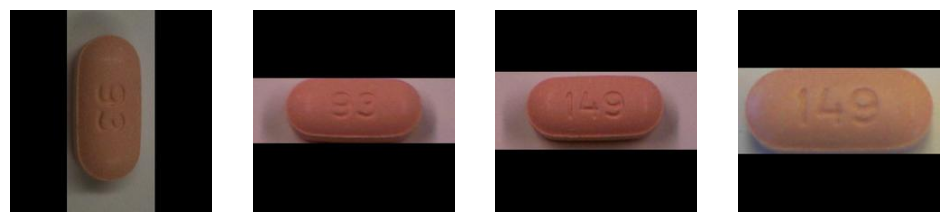

In [6]:
pid = cat.pilltype_id[0]
imgs = df[(df.pilltype_id == pid) & (~df.is_ref)]
fig, axes = plt.subplots(1, len(imgs), figsize=(3*len(imgs), 3))
for ax, (_, r) in zip(axes, imgs.iterrows()):
    ax.imshow(Image.open(EPILL / "classification_data" / r.image_path)) 
    ax.axis("off")
plt.show()

In [7]:
cons_cat = cons[cons.pilltype_id.isin(cat.pilltype_id)].copy()
cons_cat = cons_cat.sample(frac=1, random_state=42)   #shuffle
cons_cat["rank"] = cons_cat.groupby("pilltype_id").cumcount()
cons_cat["split"] = cons_cat["rank"].map(lambda r: "test" if r == 0 else ("val" if r == 1 else "train"))
ref_cat = df[df.is_ref & df.pilltype_id.isin(cat.pilltype_id)].copy()
ref_cat["split"] = "train"
all_split = pd.concat([cons_cat.drop(columns="rank"), ref_cat])
print(all_split.split.value_counts())
print(pd.crosstab(all_split.split, all_split.is_ref))



print("duplicate images:", all_split.image_path.duplicated().sum())
g = all_split.groupby("pilltype_id").split.agg(lambda s: set(s))
print("pills missing val or test:", (~g.map(lambda s: {"val", "test"} <= s)).sum())





for name in ["train", "val", "test"]:
    all_split[all_split.split == name].to_csv(OUT / f"{name}.csv", index=False)
    

split
train    188
test      40
val       40
Name: count, dtype: int64
is_ref  False  True 
split               
test       40      0
train     108     80
val        40      0
duplicate images: 0
pills missing val or test: 0


In [ ]:
stray = Path("data/processed")
print("stray folder exists:", stray.exists())
if stray.exists():
    print("stray contents:", sorted(p.name for p in stray.iterdir()))
print("catalog.csv in notebook folder:", Path("catalog.csv").exists())
print("correct folder contents:", sorted(p.name for p in OUT.iterdir()))




import shutil
if Path("catalog.csv").exists():
    shutil.move("catalog.csv", OUT / "catalog.csv")

stray folder exists: False
catalog.csv in notebook folder: True
correct folder contents: ['catalog.csv', 'test.csv', 'train.csv', 'val.csv']
